# Analisi Adattiva di Motifs e Discords

Questo notebook implementa un'analisi avanzata tramite Matrix Profile. Tutti i parametri fondamentali sono centralizzati nella **Cella di Configurazione** per permettere un adattamento dinamico dell'intera pipeline.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from sklearn.cluster import KMeans
from sktime.clustering.k_means import TimeSeriesKMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

try:
    from tslearn.shapelets import ShapeletModel
    from tslearn.utils import to_time_series_dataset
except ImportError:
    print("tslearn non trovata. Puoi installarla con !pip install tslearn")

import warnings
warnings.filterwarnings('ignore')

print("Caricamento dataset normalizzato (Instance-wise)...")
ts_data = pd.read_pickle('ts_motifs_ready.pkl.gz')
print(f"Trovate {len(ts_data)} serie storiche.")


tslearn non trovata. Puoi installarla con !pip install tslearn
Caricamento dataset normalizzato (Instance-wise)...
Trovate 4437 serie storiche.


## Pannello di Configurazione Globale
Modifica liberamente i parametri in questa cella. Tutto il codice, le estrazioni, i plot e le etichette si adatteranno in automatico!


In [4]:
# --- CONFIGURAZIONE GLOBALE ---
m = 8                          # Window size (es. 16 campionamenti = 8 ore se step=30min)
target_features = ['enmo'] # 'anglez'        # Variabile su cui calcolare il Matrix Profile (es. 'enmo', 'anglez', 'light')

k_clusters_motif = 3            # Numero di cluster desiderati per l'analisi dei Motif DTW
k_clusters_multi = 4            # Numero di cluster per l'analisi Multivariata Dataset-wise

top_k_motifs = 2                # Quanti Motif estrarre per ogni time series
top_k_discords = 2              # Quanti Discord estrarre per ogni time series

n_shapelets = 3                 # Numero di Shapelet da estrarre

# Variabile di supporto per stampare le etichette di tempo automaticamente
h_str = f"{m/2:g} ore"
print("Parametri configurati correttamente!")


Parametri configurati correttamente!


## Strategia A: Analisi sui Medoidi
Applichiamo il Matrix Profile sui medoidi pre-calcolati dal clustering globale. Questo estrae e visualizza i pattern più frequenti e le anomalie sui prototipi dei bambini.



ANALISI SULLA FEATURE: enmo


--- ANALISI DEL MEDOIDE 1583 (enmo) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(25), 56]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [169  18]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



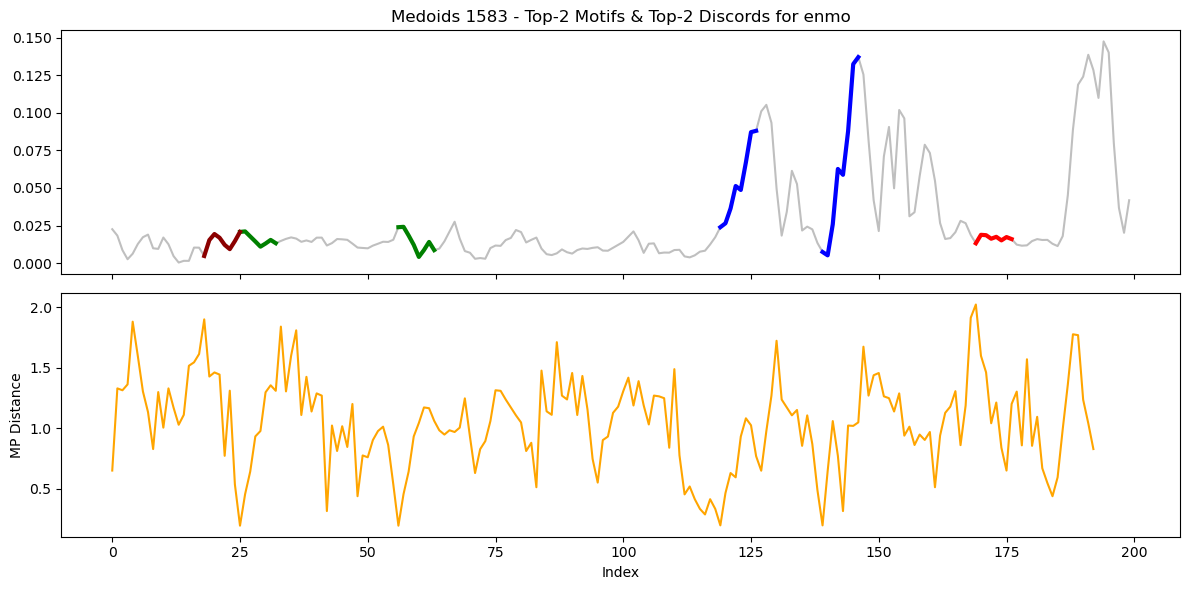


--- ANALISI DEL MEDOIDE 1606 (enmo) ---
I Top-1 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(13), np.int64(71), 98]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [140   4]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



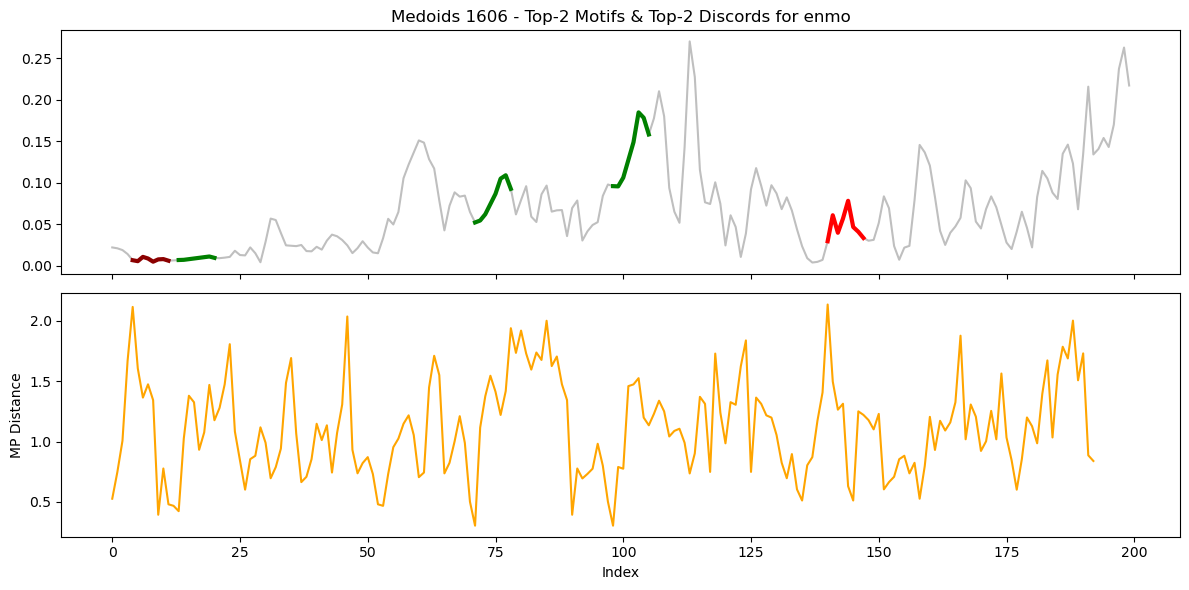


--- ANALISI DEL MEDOIDE 1248 (enmo) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(61), 100, np.int64(134), np.int64(186)]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [ 72 170]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



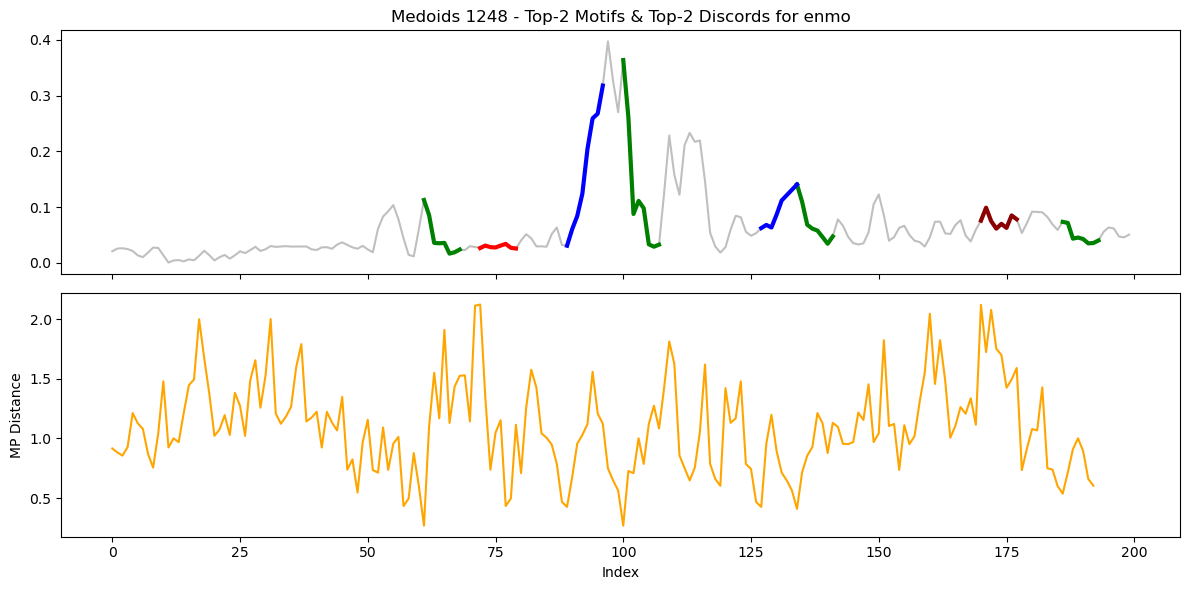

In [78]:
from matrixprofile import motifs
from matrixprofile.discords import discords

medoid_idx = [1583, 1606, 1248]
medoids = [ts_data[i] for i in medoid_idx]

for target_feature in target_features:
    print(f"\n{'='*50}\nANALISI SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    for i, ts_df in enumerate(medoids):
        ts_medoide = ts_df[target_feature].values.astype(np.float64)

        # Calcoliamo il MP con stumpy per avere la matrice base
        mp_full = stumpy.stump(ts_medoide, m)
        mp_dist = mp_full[:, 0].astype(np.float64)
        mpi = mp_full[:, 1].astype(np.int64)

        # Estrattore Motifs tramite matrixprofile-ts come richiesto
        mo, mod = motifs.motifs(ts_medoide, (mp_dist, mpi), max_motifs=top_k_motifs)
        
        # Estrattore Discords tramite matrixprofile-ts come richiesto
        anoms = discords(mp_dist, ex_zone=int(m/2), k=top_k_discords)

        print(f"\n--- ANALISI DEL MEDOIDE {medoid_idx[i]} ({target_feature}) ---")
        if len(mo) > 0:
            print(f"Top-{len(mo)} Motifs found. Example Top-1 at indices: {mo[0]}")
            print(f"   -> This means that the {h_str} blocks starting at these indices are nearly identical (routines).")
        
        if len(anoms) > 0:
            print(f"Top-{len(anoms)} Discords found at indices: {anoms}")
            print(f"   -> The {h_str} windows starting at these steps are the most unique and anomalous in the series.\n")

        # Configurazione struttura subplots originale: 1 per le TS con Motifs/Discords, 1 per il Matrix Profile
        fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
        
        # PLOT DEI MOTIFS E DISCORDS INSIEME
        axs[0].plot(ts_medoide, label=f"Time Series ('{target_feature}')", color='gray', alpha=0.5)
        axs[0].set_title(f"Medoids {medoid_idx[i]} - Top-{top_k_motifs} Motifs & Top-{top_k_discords} Discords for {target_feature}")
        
        # Plot Motifs
        colors_mo = ['g', 'b', 'black', 'm', 'y'][:max(1, len(mo))]

        for motif_group, d, c in zip(mo, mod, colors_mo):
            for idx in motif_group:
                m_shape = ts_medoide[idx : idx + m]
                axs[0].plot(range(idx, idx + m), m_shape, color=c, lw=3)
                
        # Plot Discords (in rosso)
        colors_anom = ['r', 'darkred', 'salmon', 'orange', 'k'][:max(1, len(anoms))]
        for a, c in zip(anoms, colors_anom):
            a_shape = ts_medoide[a : a + m]
            axs[0].plot(range(a, a + m), a_shape, color=c, lw=3)
            
        #axs[0].legend(loc='upper right')

        # PLOT DELLA MATRIX PROFILE DISTANCE (Valli e Picchi)
        axs[1].plot(mp_dist, color='orange')
        axs[1].set_ylabel('MP Distance')
        axs[1].set_xlabel('Index')
        
        plt.tight_layout()
        plt.show()



ANALISI SULLA FEATURE: enmo



OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.



--- ANALISI DEL MEDOIDE 1583 (enmo) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(84), 111]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [173  30]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



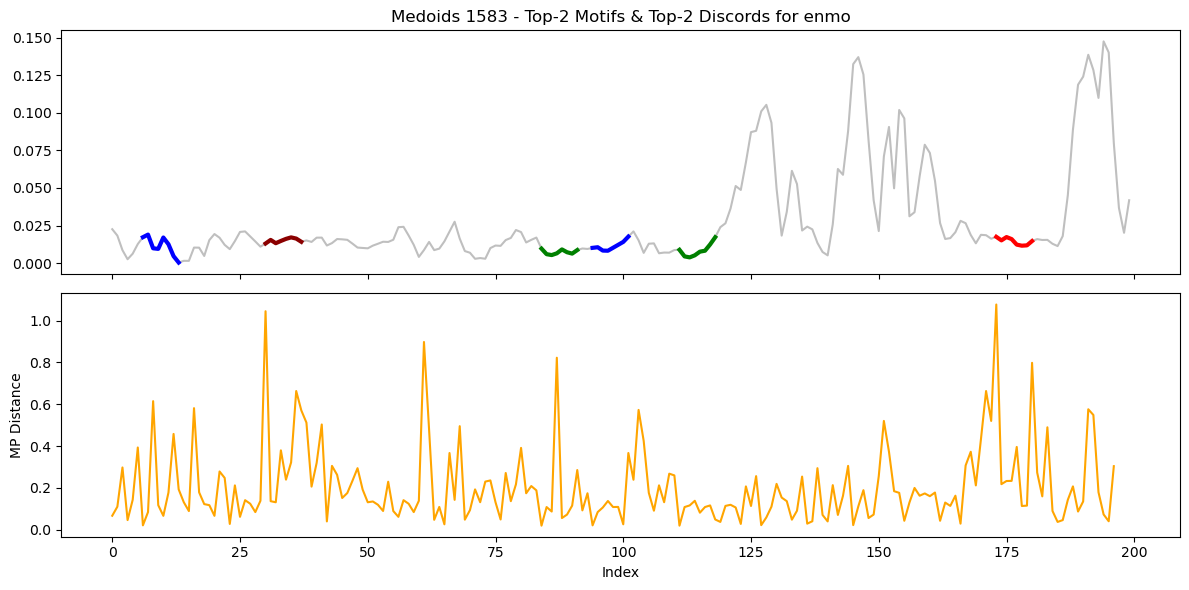


--- ANALISI DEL MEDOIDE 1606 (enmo) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(14), 16]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [130 140]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



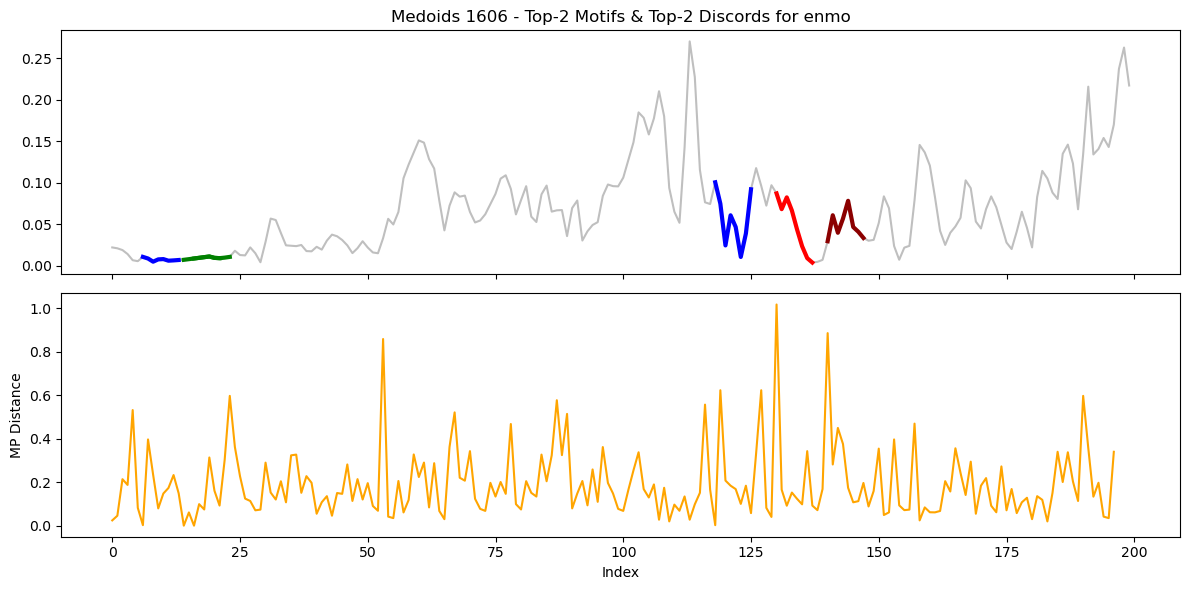


--- ANALISI DEL MEDOIDE 1248 (enmo) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(35), 131]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [172  21]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



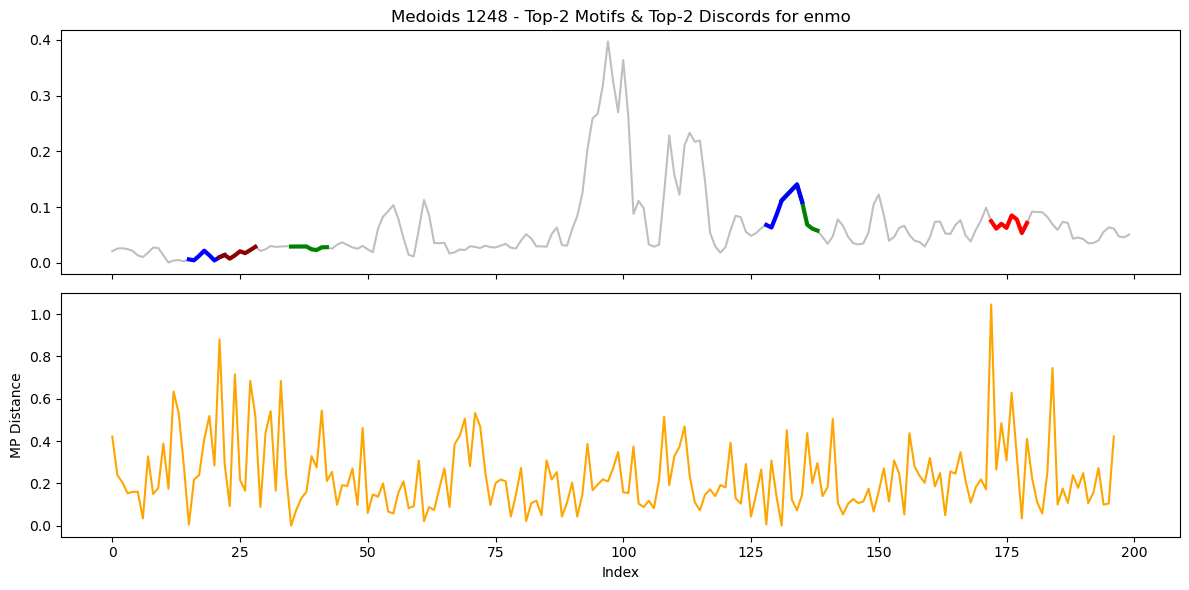

In [5]:
from matrixprofile import motifs
from matrixprofile.discords import discords

medoid_idx = [1583, 1606, 1248]
medoids = [ts_data[i] for i in medoid_idx]

for target_feature in target_features:
    print(f"\n{'='*50}\nANALISI SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    for i, ts_df in enumerate(medoids):
        ts_medoide = ts_df[target_feature].values.astype(np.float64)

        # Calcoliamo il MP con stumpy per avere la matrice base
        mp_full = stumpy.stump(ts_medoide, 4)
        mp_dist = mp_full[:, 0].astype(np.float64)
        mpi = mp_full[:, 1].astype(np.int64)

        # Estrattore Motifs tramite matrixprofile-ts come richiesto
        mo, mod = motifs.motifs(ts_medoide, (mp_dist, mpi), max_motifs=top_k_motifs)
        
        # Estrattore Discords tramite matrixprofile-ts come richiesto
        anoms = discords(mp_dist, ex_zone=int(m/2), k=top_k_discords)

        print(f"\n--- ANALISI DEL MEDOIDE {medoid_idx[i]} ({target_feature}) ---")
        if len(mo) > 0:
            print(f"Top-{len(mo)} Motifs found. Example Top-1 at indices: {mo[0]}")
            print(f"   -> This means that the {h_str} blocks starting at these indices are nearly identical (routines).")
        
        if len(anoms) > 0:
            print(f"Top-{len(anoms)} Discords found at indices: {anoms}")
            print(f"   -> The {h_str} windows starting at these steps are the most unique and anomalous in the series.\n")

        # Configurazione struttura subplots originale: 1 per le TS con Motifs/Discords, 1 per il Matrix Profile
        fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
        
        # PLOT DEI MOTIFS E DISCORDS INSIEME
        axs[0].plot(ts_medoide, label=f"Time Series ('{target_feature}')", color='gray', alpha=0.5)
        axs[0].set_title(f"Medoids {medoid_idx[i]} - Top-{top_k_motifs} Motifs & Top-{top_k_discords} Discords for {target_feature}")
        
        # Plot Motifs
        colors_mo = ['g', 'b', 'black', 'm', 'y'][:max(1, len(mo))]

        for motif_group, d, c in zip(mo, mod, colors_mo):
            for idx in motif_group:
                m_shape = ts_medoide[idx : idx + m]
                axs[0].plot(range(idx, idx + m), m_shape, color=c, lw=3)
                
        # Plot Discords (in rosso)
        colors_anom = ['r', 'darkred', 'salmon', 'orange', 'k'][:max(1, len(anoms))]
        for a, c in zip(anoms, colors_anom):
            a_shape = ts_medoide[a : a + m]
            axs[0].plot(range(a, a + m), a_shape, color=c, lw=3)
            
        #axs[0].legend(loc='upper right')

        # PLOT DELLA MATRIX PROFILE DISTANCE (Valli e Picchi)
        axs[1].plot(mp_dist, color='orange')
        axs[1].set_ylabel('MP Distance')
        axs[1].set_xlabel('Index')
        
        plt.tight_layout()
        plt.show()


## Strategia B: Estrazione Dinamica dei Motif
Questo blocco sfrutta il parametro `top_k_motifs`. Esegue iterativamente il Matrix Profile ed estrae le abitudini multiple "nascondendo" le precedenti tramite Exclusion Zone.



STRATEGIA B: ESTRAZIONE E CLUSTERING LOCALE (SHAPE-BASED)
FEATURE ANCORA: enmo

1. Estrazione dinamica e Normalizzazione Locale (Z-score) dei Top-2 Motif...
Creato dataset di 8874 forme reali (Motif non normalizzati, energia preservata) per enmo.

2. Esecuzione TimeSeriesKMeans Shape-Based (K=3) con metrica DTW...


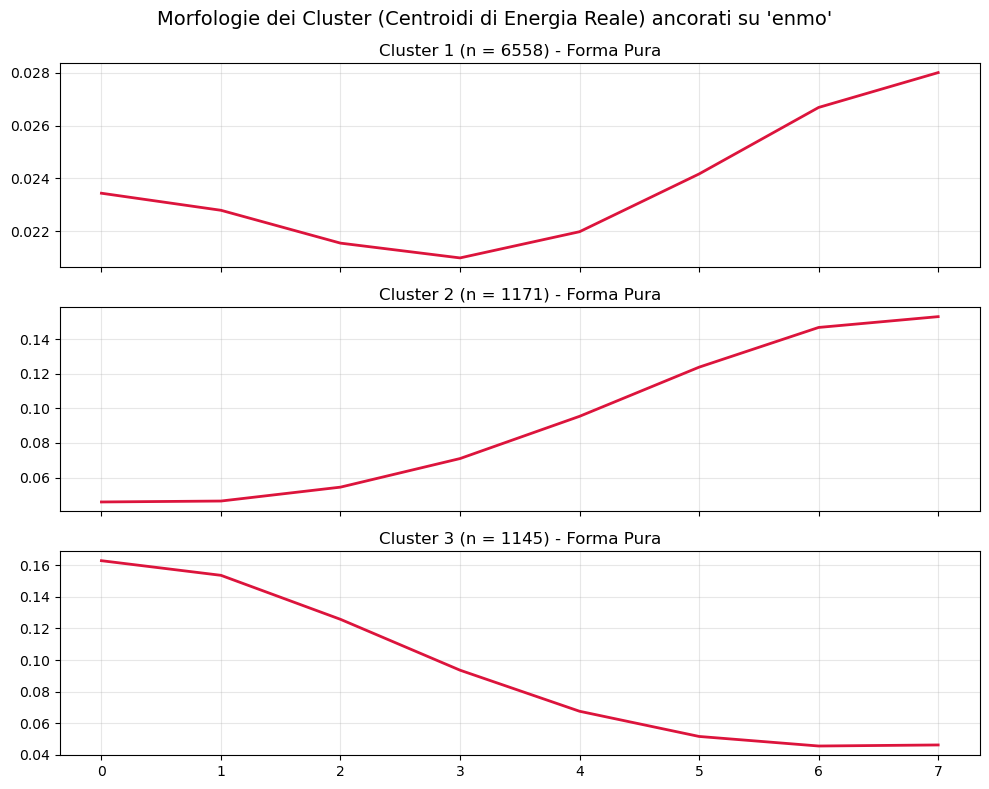

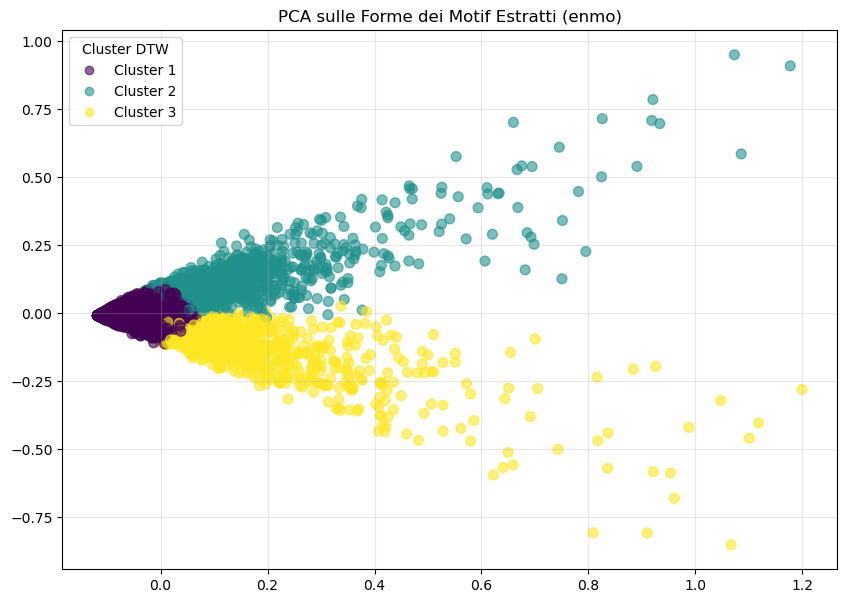


3. --- INTERPRETAZIONE CLINICA MULTIVARIATA DEI CLUSTER DI FORMA ---
Recupero dei valori assoluti reali dal contesto originario del motivo:



,enmo_raw_mean,enmo_raw_std,anglez_raw_mean,anglez_raw_std,light_raw_mean,battery_mean,sii_binary
Cluster,,,,,,,
0,0.023698,0.011653,-8.123892,12.746141,0.274150,0.266793,0.356816
1,0.092110,0.050703,-3.528196,8.243957,0.351763,0.278102,0.274125
2,0.093371,0.054757,-5.158739,8.193931,0.359723,0.276174,0.261135


- CLUSTER 1:
  * Intensità Reale (ENMO): Media 0.0237 | Varianza 0.0117
  * Postura Reale (AngleZ): Media -8.12° | Varianza 12.75
  * Luce Ambientale (Light): 0.274
  * Correlazione Problematic Internet Use: 35.7% casi problematici
- CLUSTER 2:
  * Intensità Reale (ENMO): Media 0.0921 | Varianza 0.0507
  * Postura Reale (AngleZ): Media -3.53° | Varianza 8.24
  * Luce Ambientale (Light): 0.352
  * Correlazione Problematic Internet Use: 27.4% casi problematici
- CLUSTER 3:
  * Intensità Reale (ENMO): Media 0.0934 | Varianza 0.0548
  * Postura Reale (AngleZ): Media -5.16° | Varianza 8.19
  * Luce Ambientale (Light): 0.360
  * Correlazione Problematic Internet Use: 26.1% casi problematici




In [50]:
from IPython.display import display

# Analizziamo un subset per rapidità (o l'intero dataset rimuovendo lo slicing)
subset_ts = ts_data

for target_feature in target_features:
    print(f"\n{'='*70}\nSTRATEGY B: DYNAMIC EXTRACTION AND LOCAL CLUSTERING (SHAPE-BASED)\nANCHOR FEATURE: {target_feature}\n{'='*70}\n")
    
    motif_shapes_dataset = []
    motif_context_dataset = []
    
    print(f"1. Dynamic extraction and Local Normalization (Z-score) of Top-{top_k_motifs} Motifs...")

    for i, ts_df in enumerate(subset_ts):
        ts_val = ts_df[target_feature].values.astype(np.float64)
        if len(ts_val) <= m:
            continue
            
        # Calcolo del Matrix Profile
        mp_local = stumpy.stump(ts_val, m)
        mp_dist = mp_local[:, 0].copy().astype(np.float64)
        
        # Ciclo di estrazione Top-K Motif
        for k in range(top_k_motifs):
            if np.isinf(mp_dist).all():
                break
                
            m_idx = np.argmin(mp_dist)
            motif_subseq = ts_val[m_idx : m_idx + m].copy()
            
            if not np.isnan(motif_subseq).any() and not np.isinf(mp_dist[m_idx]):
                # =========================================================
                # RIMOZIONE DELLA NORMALIZZAZIONE 
                # =========================================================
                # Non effettuiamo Z-score locale su questo segmento.
                # In questo modo il TimeSeriesKMeans (e il suo DTW) raggrupperanno
                # i Motivi non solo per la loro forma geometrica, ma anche per la
                # loro AMPLITUDINE (intensità). Un motivo piatto e sedentario avrà 
                # una distanza matematica enorme rispetto a un motivo attivo, 
                # garantendo cluster clinicamente rilevanti per la diagnosi del SII.
                
                motif_shapes_dataset.append(motif_subseq)
                
                # SALVATAGGIO CONTESTO REALE (per profilazione clinica multivariata)
                motif_raw_df = ts_df.iloc[m_idx : m_idx + m]
                context = {
                    'enmo_raw_mean': motif_raw_df['enmo'].mean() if 'enmo' in motif_raw_df.columns else np.nan,
                    'enmo_raw_std': motif_raw_df['enmo'].std() if 'enmo' in motif_raw_df.columns else np.nan,
                    'anglez_raw_mean': motif_raw_df['anglez'].mean() if 'anglez' in motif_raw_df.columns else np.nan,
                    'anglez_raw_std': motif_raw_df['anglez'].std() if 'anglez' in motif_raw_df.columns else np.nan,
                    'light_raw_mean': motif_raw_df['light'].mean() if 'light' in motif_raw_df.columns else np.nan,
                    'battery_mean': motif_raw_df['battery_voltage'].mean() if 'battery_voltage' in motif_raw_df.columns else np.nan,
                    'sii_binary': motif_raw_df['sii_binary'].iloc[0] if 'sii_binary' in motif_raw_df.columns else np.nan
                }
                motif_context_dataset.append(context)
                
            # Exclusion zone logic
            excl_start = max(0, m_idx - int(np.ceil(m/2)))
            excl_end = min(len(mp_dist), m_idx + int(np.ceil(m/2)))
            mp_dist[excl_start:excl_end] = np.inf
            
            nn_idx = mp_local[m_idx, 1]
            if nn_idx >= 0:
                excl_nn_start = max(0, nn_idx - int(np.ceil(m/2)))
                excl_nn_end = min(len(mp_dist), nn_idx + int(np.ceil(m/2)))
                mp_dist[excl_nn_start:excl_nn_end] = np.inf

    motif_shapes_dataset = np.array(motif_shapes_dataset)
    df_context = pd.DataFrame(motif_context_dataset)
    print(f"Created dataset of {motif_shapes_dataset.shape[0]} real shapes (unnormalized Motifs, energy preserved) for {target_feature}.")

    # CLUSTERING SHAPE-BASED (DTW)
    print(f"\n2. Executing TimeSeriesKMeans Shape-Based (K={k_clusters_motif}) with DTW metric...")
    kmeans_dtw = TimeSeriesKMeans(n_clusters=k_clusters_motif, metric="dtw", init_algorithm="kmeans++", n_init=5, random_state=42)
    motif_clusters = kmeans_dtw.fit_predict(motif_shapes_dataset)
    df_context['Cluster'] = motif_clusters

    # VISUALIZZAZIONE DELLE MORFOLOGIE (Centroidi)
    fig, axs = plt.subplots(k_clusters_motif, 1, figsize=(10, 8), sharex=True)
    fig.suptitle(f"Cluster Morphologies (Real Energy Centroids) anchored on '{target_feature}'", fontsize=14)
    for i in range(k_clusters_motif):
        centroid = kmeans_dtw.cluster_centers_[i].flatten()
        axs[i].plot(centroid, color='crimson', linewidth=2)
        axs[i].set_title(f'Cluster {i+1} (n = {sum(motif_clusters==i)}) - Real Shape')
        axs[i].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # PCA
    pca = PCA(n_components=2)
    motif_pca = pca.fit_transform(motif_shapes_dataset)
    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(motif_pca[:, 0], motif_pca[:, 1], c=motif_clusters, cmap='viridis', alpha=0.6, s=50)
    handles, _ = scatter.legend_elements()
    plt.legend(handles, [f"Cluster {i+1}" for i in range(k_clusters_motif)], title="Cluster DTW")
    plt.title(f"PCA on Extracted Motif Shapes ({target_feature})")
    plt.grid(True, alpha=0.3)
    plt.show()

    # PROFILING MULTIVARIATO
    print(f"\n3. --- MULTIVARIATE CLINICAL INTERPRETATION OF SHAPE CLUSTERS ---")
    print("Retrieving real absolute values from the original context of the motif:\n")
    
    cluster_profiles = df_context.groupby('Cluster').mean()
    display(cluster_profiles)
    
    for i, row in cluster_profiles.iterrows():
        print(f"- CLUSTER {i+1}:")
        if 'enmo_raw_mean' in row:
            print(f"  * Real Intensity (ENMO): Mean {row['enmo_raw_mean']:.4f} | Std {row.get('enmo_raw_std', 0):.4f}")
        if 'anglez_raw_mean' in row:
            print(f"  * Real Posture (AngleZ): Mean {row['anglez_raw_mean']:.2f}° | Std {row.get('anglez_raw_std', 0):.2f}")
        if 'light_raw_mean' in row:
            print(f"  * Ambient Light (Light): {row['light_raw_mean']:.3f}")
        if 'sii_binary' in row and not np.isnan(row['sii_binary']):
            print(f"  * Problematic Internet Use Correlation: {row['sii_binary']*100:.1f}% problematic cases")
    print("\n")
